In [64]:
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import mean_absolute_error, mean_squared_error
from pathlib import Path
import joblib
import json

In [2]:
temperatures = pd.Series([600, 610, 620, 630, 640])

rolling_avg = temperatures.rolling(
    window = 3,
    min_periods = 1
).mean()

print(rolling_avg)

0    600.0
1    605.0
2    610.0
3    620.0
4    630.0
dtype: float64


In [3]:
data = pd.DataFrame({
    "unit_id": [1, 1, 1, 2, 2, 2],
    "cycle": [1, 2, 3, 1, 2, 3],
    "temperature": [600, 610, 620, 700, 710, 720]
})

data["rolling_temp"] = (
    data.groupby("unit_id")["temperature"]
    .transform(lambda x: x.rolling(window = 2, min_periods = 1).mean())
)

print(data)

   unit_id  cycle  temperature  rolling_temp
0        1      1          600         600.0
1        1      2          610         605.0
2        1      3          620         615.0
3        2      1          700         700.0
4        2      2          710         705.0
5        2      3          720         715.0


In [ ]:
# Load NASA C-MAPSS FD001 training data
columns = (
    ["unit_id", "cycle"]
    + [f"operational_setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

data_path = Path("../data/raw/train_FD001.txt")

train_df = pd.read_csv(
    data_path,
    sep = r"\s+",
    header = None,
    names = columns
)

# Sort observations chronologically for each engine
train_df = train_df.sort_values(
    ["unit_id", "cycle"]
).reset_index(drop=True)

# Calculate Remaining Useful Life
train_df["RUL"] = (
    train_df.groupby("unit_id")["cycle"].transform("max")
    - train_df["cycle"]
)

# Remove constant sensor columns
sensor_columns = [
    col for col in train_df.columns
    if col.startswith("sensor_") and train_df[col].nunique() > 1
]

# Split by engine ID to prevent data leakage
engine_ids = train_df["unit_id"].unique()

train_ids, val_ids = train_test_split(
    engine_ids,
    test_size=0.2,
    random_state=42
)

train_mask = train_df["unit_id"].isin(train_ids)
val_mask = train_df["unit_id"].isin(val_ids)

# Verify preparation
print("Dataset shape:", train_df.shape)
print("Number of sensors:", len(sensor_columns))
print("Training engines:", len(train_ids))
print("Validation engines:", len(val_ids))
print("Training observations:", train_mask.sum())
print("Validation observations:", val_mask.sum())
print("Engine overlap:", len(np.intersect1d(train_ids, val_ids)))

train_df.head()


Dataset shape: (20631, 27)
Number of sensors: 15
Training engines: 80
Validation engines: 20
Training observations: 16561
Validation observations: 4070
Engine overlap: 0


,unit_id,cycle,operational_setting_1,operational_setting_2,operational_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,RUL
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,191
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,190
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,189
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,188
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,187


In [ ]:
# Calculate a 5-cycle rolling average for sensor 11 for each engine
# This reduces short-term fluctuations and makes degradation trends easier to identify
# Grouping by unit_id ensures readings from different engines are never mixed
# min_periods = 1 allows the avaerage to be calculated even for the first few cycles
train_df["sensor_11_rolling_mean"] = (
    train_df.groupby("unit_id")["sensor_11"].transform(
        lambda x: x.rolling(window = 5, min_periods = 1).mean()
    )
)

train_df[
    ["unit_id", "cycle", "sensor_11", "sensor_11_rolling_mean"]
].head(10)

,unit_id,cycle,sensor_11,sensor_11_rolling_mean
0,1,1,47.47,47.470
1,1,2,47.49,47.480
2,1,3,47.27,47.410
3,1,4,47.13,47.340
4,1,5,47.28,47.328
5,1,6,47.16,47.266
6,1,7,47.36,47.240
7,1,8,47.24,47.234
8,1,9,47.29,47.266
9,1,10,47.03,47.216


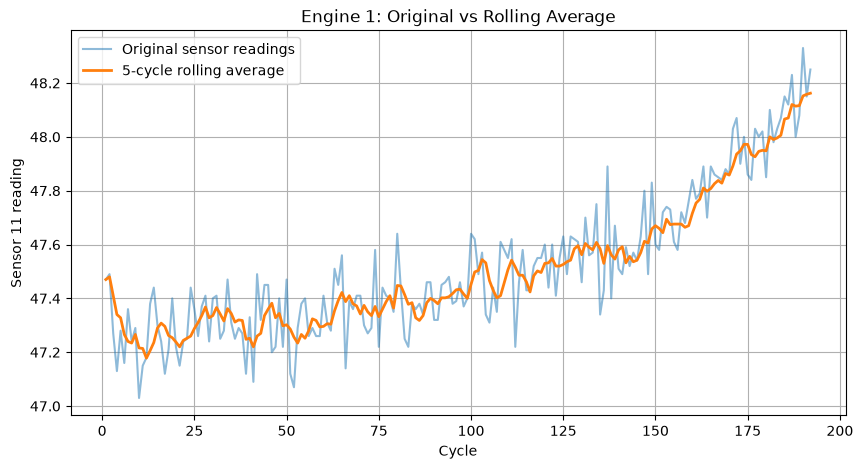

In [ ]:
# Select Engine 1 to visualise the effect of rolling average feature engineering
engine_1 = train_df[train_df["unit_id"] == 1]

# Compare the original sensor 11 readings against their 5-cycle rolling average
# The smooth curve helps reveal gradual degredation patterns that maybe obscured by fluctuations in the original readings
plt.figure(figsize = (10, 5))

plt.plot(
    engine_1["cycle"],
    engine_1["sensor_11"],
    label = "Original sensor readings",
    alpha = 0.5
)

plt.plot(
    engine_1["cycle"],
    engine_1["sensor_11_rolling_mean"],
    label = "5-cycle rolling average",
    linewidth = 2
)

plt.xlabel("Cycle")
plt.ylabel("Sensor 11 reading")
plt.title("Engine 1: Original vs Rolling Average")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Calculate a 5-cycle rolling average for Sensor 12 for each engine.
# This captures the underlying sensor trend while reducing measurement noise.
# Only the current and previous four readings are used, preventing future-data leakage.
train_df["sensor_12_rolling_mean"] = (
    train_df.groupby("unit_id")["sensor_12"].transform(
        lambda x: x.rolling(window=5, min_periods=1).mean()
    )
)

In [ ]:
# Define the newly engineered features that capture recent sensor behavior
rolling_features = [
    "sensor_11_rolling_mean",
    "sensor_12_rolling_mean"
]

# Combine the 15 original non-constant sensors with the 2 engineered features
# These features will be used as inputs to the updated neural network
feature_columns = sensor_columns + rolling_features

# Verify the total number of input features and their names
print("Number of features:", len(feature_columns))
print(feature_columns)

Number of features: 17
['sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21', 'sensor_11_rolling_mean', 'sensor_12_rolling_mean']


In [17]:
# Select the 17 input features for training and validation
X_train = train_df.loc[train_mask, feature_columns]
X_val = train_df.loc[val_mask, feature_columns]

# Select the original RUL targets
y_train = train_df.loc[train_mask, "RUL"]
y_val = train_df.loc[val_mask, "RUL"]

# Verify the dimensions of the datasets
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("y_train:", y_train.shape)
print("y_val:", y_val.shape)


X_train: (16561, 17)
X_val: (4070, 17)
y_train: (16561,)
y_val: (4070,)


In [18]:
# Initialize the feature scaler
scaler = StandardScaler()

# Learn the mean and standard deviation from training data,
# then standardize all 17 training features
X_train_scaled = scaler.fit_transform(X_train)

# Standardize validation features using training statistics
# Do not fit the scaleron validation data
X_val_scaled = scaler.transform(X_val)

# Verify that the scaling preserves the dataset dimensions
print("Training:", X_train.shape)
print("Validation:", X_val_scaled.shape)

Training: (16561, 17)
Validation: (4070, 17)


In [21]:
# Convert scaled training and validation features into PyTorch tensors.
X_train_tensor = torch.tensor(X_train_scaled, dtype = torch.float32)
X_val_tensor = torch.tensor(X_val_scaled, dtype = torch.float32)

# Convert the original RUL targets into PyTorch tensors.
y_train_tensor = torch.tensor(y_train.to_numpy(), dtype = torch.float32)
y_val_tensor = torch.tensor(y_val.to_numpy(), dtype = torch.float32)

# Add a second dimension so each target has shape (1,).
y_train_tensor = y_train_tensor.unsqueeze(1)
y_val_tensor = y_val_tensor.unsqueeze(1)

# Verify tensor dimensions.
print("X_train:", X_train_tensor.shape)
print("X_val:", X_val_tensor.shape)
print("y_train:", y_train_tensor.shape)
print("y_val:", y_val_tensor.shape)

X_train: torch.Size([16561, 17])
X_val: torch.Size([4070, 17])
y_train: torch.Size([16561, 1])
y_val: torch.Size([4070, 1])


In [22]:
# Pair each observation's features with its corresponding RUL target.
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)

# Create mini-batches for training and validation.
batch_size = 64

train_loader = DataLoader(
    train_dataset,
    batch_size = batch_size,
    shuffle = True
)

val_loader = DataLoader(
    val_dataset,
    batch_size = batch_size,
    shuffle = False
)

# Examine the dimensions of one training batch.
X_batch, y_batch = next(iter(train_loader))

print("Input batch:", X_batch.shape)
print("Target batch:", y_batch.shape)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Input batch: torch.Size([64, 17])
Target batch: torch.Size([64, 1])
Training batches: 259
Validation batches: 64


In [24]:
# Define the neural network architecture.
class RULPredictor(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(17, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x)

In [25]:
# Create an instance of Neural Network
model = RULPredictor()

# Define the loss function
loss_fn = nn.MSELoss()

# Define the optimizer
optimizer = torch.optim.Adam(model.parameters(), lr = 0.001)

# Display the model architecture
print(model)

RULPredictor(
  (network): Sequential(
    (0): Linear(in_features=17, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [26]:
# Put the neural network into training mode.
model.train()

# Get one batch of engine observations and RUL targets.
X_batch, y_batch = next(iter(train_loader))

# Clear gradients from previous calculations.
optimizer.zero_grad()

# Forward pass to predict RUL.
predictions = model(X_batch)

# Calculate the difference between predictions and actual RUL.
loss = loss_fn(predictions, y_batch)

# Backpropagation: calculate gradients.
loss.backward()

# Update the model's weights and biases.
optimizer.step()

# Display the loss for this batch.
print("Batch loss:", loss.item())

Batch loss: 14012.4248046875


In [27]:
# Initialize a fresh model for this experiment.
model = RULPredictor()

# Define the loss function and optimizer.
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

num_epochs = 10

# Store losses so we can visualize training later.
train_losses = []
val_losses = []

for epoch in range(num_epochs):

    # Training phase
    model.train()
    total_train_loss = 0

    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()

        predictions = model(X_batch)
        loss = loss_fn(predictions, y_batch)

        loss.backward()
        optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    avg_train_loss = total_train_loss / len(train_dataset)
    train_losses.append(avg_train_loss)

    # Validation phase
    model.eval()
    total_val_loss = 0

    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            predictions = model(X_batch)
            loss = loss_fn(predictions, y_batch)

            total_val_loss += loss.item() * X_batch.size(0)

    avg_val_loss = total_val_loss / len(val_dataset)
    val_losses.append(avg_val_loss)

    print(
        f"Epoch {epoch+1}/{num_epochs} | "
        f"Train RMSE: {avg_train_loss**0.5:.2f} | "
        f"Val RMSE: {avg_val_loss**0.5:.2f}"
    )

Epoch 1/10 | Train RMSE: 98.39 | Val RMSE: 56.55
Epoch 2/10 | Train RMSE: 55.37 | Val RMSE: 40.07
Epoch 3/10 | Train RMSE: 46.74 | Val RMSE: 35.57
Epoch 4/10 | Train RMSE: 44.27 | Val RMSE: 34.90
Epoch 5/10 | Train RMSE: 43.59 | Val RMSE: 34.40
Epoch 6/10 | Train RMSE: 42.94 | Val RMSE: 34.42
Epoch 7/10 | Train RMSE: 42.73 | Val RMSE: 34.30
Epoch 8/10 | Train RMSE: 42.69 | Val RMSE: 34.36
Epoch 9/10 | Train RMSE: 42.58 | Val RMSE: 34.36
Epoch 10/10 | Train RMSE: 42.53 | Val RMSE: 34.10


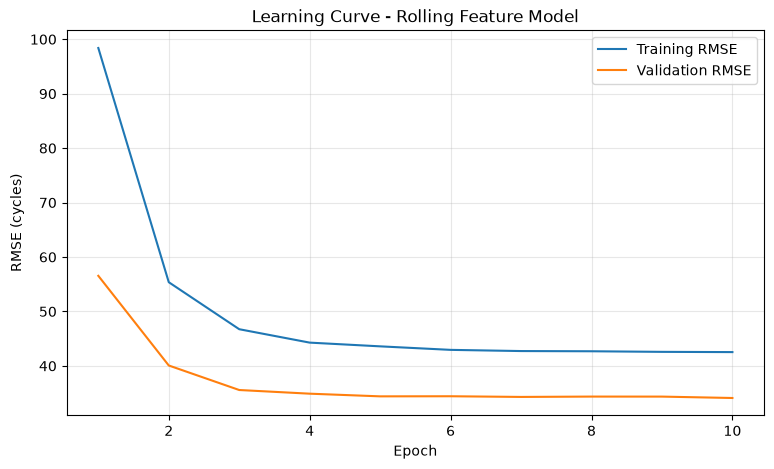

In [29]:
# Convert MSE losses into RMSE.
train_rmse = np.sqrt(train_losses)
val_rmse = np.sqrt(val_losses)

# Create epoch numbers.
epochs = range(1, len(train_rmse) + 1)

# Plot training and validation performance.
plt.figure(figsize=(9, 5))

plt.plot(epochs, train_rmse, label = "Training RMSE")
plt.plot(epochs, val_rmse, label = "Validation RMSE")

plt.xlabel("Epoch")
plt.ylabel("RMSE (cycles)")
plt.title("Learning Curve - Rolling Feature Model")
plt.legend()
plt.grid(alpha = 0.3)
plt.show()

In [31]:
# Set the random seed.
torch.manual_seed(42) # Initialize PyTorch's random number generators

# Generate some random numbers.
numbers_1 = torch.rand(5)

# Reset the same seed.
torch.manual_seed(42)

# Generate another set of random numbers.
numbers_2 = torch.rand(5)

print("First:", numbers_1)
print("Second:", numbers_2)

print("Identical:", torch.equal(numbers_1, numbers_2))

First: tensor([0.8823, 0.9150, 0.3829, 0.9593, 0.3904])
Second: tensor([0.8823, 0.9150, 0.3829, 0.9593, 0.3904])
Identical: True


## Experiment 2: Controlled Model Comparison

In [32]:
# Prepare the original 15-feature dataset
X_train_15 = train_df.loc[train_mask, sensor_columns]
X_val_15 = train_df.loc[val_mask, sensor_columns]

scaler_15 = StandardScaler()

X_train_15_scaled = scaler_15.fit_transform(X_train_15)
X_val_15_scaled = scaler_15.transform(X_val_15)

# Convert to PyTorch Tensors
X_train_15_tensor = torch.tensor(X_train_15_scaled, dtype = torch.float32)
X_val_15_tensor = torch.tensor(X_val_15_scaled, dtype = torch.float32)


print("Original training:", X_train_15_tensor.shape)
print("Original validation:", X_val_15_tensor.shape)

print("Engineered training:", X_train_tensor.shape)
print("Engineered validation:", X_val_tensor.shape)


Original training: torch.Size([16561, 15])
Original validation: torch.Size([4070, 15])
Engineered training: torch.Size([16561, 17])
Engineered validation: torch.Size([4070, 17])


In [33]:
# Define a Neural Network that accepts different numbers of input features
class ComparisonRULPredictor(nn.Module):
    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x)

In [34]:
# Reusable training function
def train_and_evaluate(X_train, X_val, y_train, y_val, seed):
    # Set random seed for reproducibility
    torch.manual_seed(seed)

    # Determine how many inputs the model needs
    input_size = X_train.shape[1]

    # Create a fresh NN
    model = ComparisonRULPredictor(input_size = input_size)

    # Define the loss function and oprimizer
    loss_fn = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr = 0.001)

    # Pair features with their corresponding RUL targets.
    train_dataset = TensorDataset(X_train, y_train)
    val_dataset = TensorDataset(X_val, y_val)

    # Create DataLoaders.
    train_loader = DataLoader(
        train_dataset,
        batch_size = 64,
        shuffle = True
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size = 64,
        shuffle = False
    )

    # Number of training epochs.
    num_epochs = 10

    # Train the model.
    for epoch in range(num_epochs):
        model.train()

        for X_batch, y_batch in train_loader:
            optimizer.zero_grad()
            predictions = model(X_batch)
            loss = loss_fn(predictions, y_batch)

            # Calculate the gradients
            loss.backward()

            # Update model parameters.
            optimizer.step()

    # Evaluate the trained model.
    model.eval()
    total_val_loss = 0.0

    with torch.no_grad():
        for X_batch, y_batch in val_loader:

            # Predict RUL for validation observations.
            predictions = model(X_batch)

            # Calculate validation loss.
            loss = loss_fn(predictions, y_batch)

            # Accumulate squared errors across observations.
            total_val_loss += loss.item() * X_batch.size(0)

    # Calculate RMSE across the entire validation dataset.
    val_mse = total_val_loss / len(val_dataset)
    val_rmse = val_mse ** 0.5

    return val_rmse


In [35]:
# Train the original 15-feature model using seed 42.
rmse_15 = train_and_evaluate(
    X_train_15_tensor,
    X_val_15_tensor,
    y_train_tensor,
    y_val_tensor,
    seed = 42
)

# Display the validation RMSE.
print(f"15-feature model RMSE: {rmse_15:.2f} cycles")

15-feature model RMSE: 35.03 cycles


In [36]:
# Train the engineered 17-feature model using seed 42.
rmse_17 = train_and_evaluate(
    X_train_tensor,
    X_val_tensor,
    y_train_tensor,
    y_val_tensor,
    seed = 42
)

# Display the validation RMSE.
print(f"17-feature model RMSE: {rmse_17:.2f} cycles")

# Compare both models.
print(f"15-feature model RMSE: {rmse_15:.2f} cycles")
print(f"Difference: {rmse_15 - rmse_17:.2f} cycles")

17-feature model RMSE: 34.49 cycles
15-feature model RMSE: 35.03 cycles
Difference: 0.54 cycles


In [37]:
# Random seeds for our controlled experiment.
seeds = [42, 123, 456, 789, 2026]

# Store validation RMSE for both models.
results_15 = []
results_17 = []

for seed in seeds:

    # Train the original 15-feature model.
    rmse_15 = train_and_evaluate(
        X_train_15_tensor,
        X_val_15_tensor,
        y_train_tensor,
        y_val_tensor,
        seed = seed
    )

    # Train the engineered 17-feature model.
    rmse_17 = train_and_evaluate(
        X_train_tensor,
        X_val_tensor,
        y_train_tensor,
        y_val_tensor,
        seed = seed
    )

    # Store the results.
    results_15.append(rmse_15)
    results_17.append(rmse_17)

    print(
        f"Seed {seed} | "
        f"15 features: {rmse_15:.2f} | "
        f"17 features: {rmse_17:.2f}"
    )

Seed 42 | 15 features: 35.03 | 17 features: 34.49
Seed 123 | 15 features: 35.25 | 17 features: 34.18
Seed 456 | 15 features: 34.70 | 17 features: 34.31
Seed 789 | 15 features: 34.66 | 17 features: 34.27
Seed 2026 | 15 features: 34.73 | 17 features: 34.16


In [38]:
# Calculate average validation RMSE across five seeds.
mean_15 = np.mean(results_15)
mean_17 = np.mean(results_17)

# Calculate sample standard deviation across runs.
std_15 = np.std(results_15, ddof = 1)
std_17 = np.std(results_17, ddof = 1)

# Calculate improvement for each seed.
improvements = np.array(results_15) - np.array(results_17)

# Calculate average improvement.
mean_improvement = np.mean(improvements)

print(f"15-feature model: {mean_15:.2f} ± {std_15:.2f} cycles")
print(f"17-feature model: {mean_17:.2f} ± {std_17:.2f} cycles")
print(f"Average improvement: {mean_improvement:.2f} cycles")
print(f"Improved in {np.sum(improvements > 0)} out of {len(improvements)} runs")

15-feature model: 34.87 ± 0.25 cycles
17-feature model: 34.28 ± 0.13 cycles
Average improvement: 0.59 cycles
Improved in 5 out of 5 runs


### Experiment 2: Results and Interpretation

**Objective:** Determine whether adding 5-cycle rolling-average features for sensors 11 and 12 improves RUL prediction.

**Methodology:** Compared two PyTorch neural networks with identical hidden-layer architectures (64 and 32 neurons), learning rate (0.001), training epochs (10), and engine-level train/validation split. Each model was trained using five random seeds.

**Results:**

| Metric | Original (15 features) | Engineered (17 features) |
|---|---:|---:|
| Mean validation RMSE | 34.87 cycles | 34.28 cycles |
| Standard deviation | 0.25 cycles | 0.13 cycles |

The engineered model achieved an average RMSE improvement of approximately 0.59 cycles (1.69%) and outperformed the original model in all five runs.

**Conclusion:** The rolling-average features produced a small but consistent improvement in validation performance across the tested random seeds. The engineered model also showed lower variability between training runs.

**Limitations:** The comparison used five random seeds and one fixed validation split. Further evaluation on the held-out NASA C-MAPSS FD001 test dataset is required to assess generalization.

## Final Evaluation: NASA FD001 Test Dataset

In [39]:
# Load the official NASA FD001 test dataset.
test_df = pd.read_csv(
    "../data/raw/test_FD001.txt",
    sep = r"\s+",
    header = None
)

# Load the true remaining useful life values.
true_rul = pd.read_csv(
    "../data/raw/RUL_FD001.txt",
    sep = r"\s+",
    header = None
)

# Inspect the dimensions.
print("Test dataset shape:", test_df.shape)
print("True RUL shape:", true_rul.shape)

# Preview the first five rows.
display(test_df.head())
display(true_rul.head())

Test dataset shape: (13096, 26)
True RUL shape: (100, 1)


,0,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
0,1,1,0.0023,0.0003,100.0,518.67,643.02,1585.29,1398.21,14.62,...,521.72,2388.03,8125.55,8.4052,0.03,392,2388,100.0,38.86,23.3735
1,1,2,-0.0027,-0.0003,100.0,518.67,641.71,1588.45,1395.42,14.62,...,522.16,2388.06,8139.62,8.3803,0.03,393,2388,100.0,39.02,23.3916
2,1,3,0.0003,0.0001,100.0,518.67,642.46,1586.94,1401.34,14.62,...,521.97,2388.03,8130.10,8.4441,0.03,393,2388,100.0,39.08,23.4166
3,1,4,0.0042,0.0000,100.0,518.67,642.44,1584.12,1406.42,14.62,...,521.38,2388.05,8132.90,8.3917,0.03,391,2388,100.0,39.00,23.3737
4,1,5,0.0014,0.0000,100.0,518.67,642.51,1587.19,1401.92,14.62,...,522.15,2388.03,8129.54,8.4031,0.03,390,2388,100.0,38.99,23.4130


,0
0,112
1,98
2,69
3,82
4,91


In [40]:
test_df.columns = (
    ["unit_id", "cycle"]
    + [f"operational_setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

true_rul.columns = ["RUL"]

print(test_df.columns.tolist())
print(test_df["unit_id"].nunique())

['unit_id', 'cycle', 'operational_setting_1', 'operational_setting_2', 'operational_setting_3', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21']
100


In [41]:
rolling_sensors = ["sensor_11", "sensor_12"]

for sensor in rolling_sensors:
    test_df[f"{sensor}_rolling_mean"] = (
        test_df.groupby("unit_id")[sensor]
        .transform(lambda x: x.rolling(window=5, min_periods=1).mean())
    )

test_df[
    ["unit_id", "cycle", "sensor_11", "sensor_11_rolling_mean",
     "sensor_12", "sensor_12_rolling_mean"]
].head(10)

,unit_id,cycle,sensor_11,sensor_11_rolling_mean,sensor_12,sensor_12_rolling_mean
0,1,1,47.20,47.200,521.72,521.7200
1,1,2,47.50,47.350,522.16,521.9400
2,1,3,47.50,47.400,521.97,521.9500
3,1,4,47.28,47.370,521.38,521.8075
4,1,5,47.31,47.358,522.15,521.8760
5,1,6,47.26,47.370,521.92,521.9160
6,1,7,47.31,47.332,522.01,521.8860
7,1,8,47.21,47.274,522.09,521.9100
8,1,9,47.37,47.292,522.03,522.0400
9,1,10,47.14,47.258,522.00,522.0100


In [42]:
test_last = (
    test_df.sort_values(["unit_id", "cycle"])
    .groupby("unit_id")
    .tail(1)
    .sort_values("unit_id")
    .reset_index(drop = True)
)

print("Final observations shape:", test_last.shape)
print("Number of engines:", test_last["unit_id"].nunique())

display(test_last[["unit_id", "cycle"]].head())

Final observations shape: (100, 28)
Number of engines: 100


,unit_id,cycle
0,1,31
1,2,49
2,3,126
3,4,106
4,5,98


In [43]:
X_test = test_last[feature_columns]

print("Test features shape:", X_test.shape)
print("Missing values:", X_test.isna().sum().sum())

Test features shape: (100, 17)
Missing values: 0


In [44]:
# Prepare all original training observations using our selected 17 features
X_full_train = train_df[feature_columns]

# Prepare the corresponding RUL targets
y_full_train = train_df["RUL"]

print("Full training features:", X_full_train.shape)
print("Full training targets:", y_full_train.shape)

Full training features: (20631, 17)
Full training targets: (20631,)


In [45]:
# Create a new scaler for the final model
final_scaler = StandardScaler()

# Fit on all 100 training engines
X_full_train_scaled = final_scaler.fit_transform(X_full_train)

# Transform the test features using the same scaler
X_test_scaled = final_scaler.transform(X_test)

print("Scaled training shape:", X_full_train_scaled.shape)
print("Scaled test shape:", X_test_scaled.shape)

Scaled training shape: (20631, 17)
Scaled test shape: (100, 17)


In [46]:
# Convert the final training features into a tensor
X_full_train_tensor = torch.tensor(
    X_full_train_scaled, dtype = torch.float32
)

# Convert the training targets into a tensor
y_full_train_tensor = torch.tensor(
    y_full_train.to_numpy(), dtype = torch.float32
).unsqueeze(1)

# Convert the test features into a tensor
X_test_tensor = torch.tensor(
    X_test_scaled, dtype = torch.float32
)

print("Training features:", X_full_train_tensor.shape)
print("Training targets:", y_full_train_tensor.shape)
print("Test features:", X_test_tensor.shape)

Training features: torch.Size([20631, 17])
Training targets: torch.Size([20631, 1])
Test features: torch.Size([100, 17])


In [47]:
final_train_dataset = TensorDataset(
    X_full_train_tensor,
    y_full_train_tensor
)

final_train_loader = DataLoader(
    final_train_dataset,
    batch_size = 64,
    shuffle = True
)

print("Training observations:", len(final_train_dataset))
print("Number of batches:", len(final_train_loader))

Training observations: 20631
Number of batches: 323


In [48]:
# Set the random seed for reproducibility
torch.manual_seed(42)

# Initialize our final 17-feature neural network
final_model = ComparisonRULPredictor(input_size=17)

# Define the loss function and optimizer
final_criterion = nn.MSELoss()

final_optimizer = torch.optim.Adam(
    final_model.parameters(),
    lr = 0.001
)

print(final_model)

ComparisonRULPredictor(
  (network): Sequential(
    (0): Linear(in_features=17, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [49]:
final_epochs = 10

for epoch in range(final_epochs):
    final_model.train()
    total_loss = 0.0

    for X_batch, y_batch in final_train_loader:
        final_optimizer.zero_grad()

        predictions = final_model(X_batch)
        loss = final_criterion(predictions, y_batch)

        loss.backward()
        final_optimizer.step()

        total_loss += loss.item() * X_batch.size(0)

    train_mse = total_loss / len(final_train_dataset)
    train_rmse = train_mse ** 0.5

    print(f"Epoch {epoch + 1}/{final_epochs} | Training RMSE: {train_rmse:.2f}")

Epoch 1/10 | Training RMSE: 89.13
Epoch 2/10 | Training RMSE: 47.93
Epoch 3/10 | Training RMSE: 42.89
Epoch 4/10 | Training RMSE: 42.25
Epoch 5/10 | Training RMSE: 42.15
Epoch 6/10 | Training RMSE: 41.92
Epoch 7/10 | Training RMSE: 41.37
Epoch 8/10 | Training RMSE: 41.17
Epoch 9/10 | Training RMSE: 41.08
Epoch 10/10 | Training RMSE: 40.98


In [50]:
# Switch the model to evaluation mode
final_model.eval()

# Generate predictions without tracking gradients
with torch.no_grad():
    test_predictions = final_model(X_test_tensor)

print("Prediction shape:", test_predictions.shape)
print("First 5 predictions:")
print(test_predictions[:5])

Prediction shape: torch.Size([100, 1])
First 5 predictions:
tensor([[174.9874],
        [155.1139],
        [ 72.6926],
        [102.1815],
        [131.7216]])


In [51]:
# Convert predictions to a NumPy array
y_pred = test_predictions.squeeze(1).numpy()

# Check the prediction range
print("Minimum predicted RUL:", y_pred.min())
print("Maximum predicted RUL:", y_pred.max())

# Count negative predictions
print("Negative predictions:", (y_pred < 0).sum())

Minimum predicted RUL: 9.953079
Maximum predicted RUL: 189.01111
Negative predictions: 0


In [53]:
# Extract the 100 actual RUL values
y_test = true_rul["RUL"].to_numpy()

# Calculate the final evaluation metrics
test_mae = mean_absolute_error(y_test, y_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"Final Test MAE: {test_mae:.2f} cycles")
print(f"Final Test RMSE: {test_rmse:.2f} cycles")

Final Test MAE: 24.14 cycles
Final Test RMSE: 32.90 cycles


In [54]:
# Calculate prediction errors
errors = y_pred - y_test

# Count overpredictions and underpredictions
overpredictions = (errors > 0).sum()
underpredictions = (errors < 0).sum()

# Calculate the average signed error
mean_error = errors.mean()

print(f"Overpredictions: {overpredictions}")
print(f"Underpredictions: {underpredictions}")
print(f"Mean signed error: {mean_error:.2f} cycles")

Overpredictions: 86
Underpredictions: 14
Mean signed error: 20.50 cycles


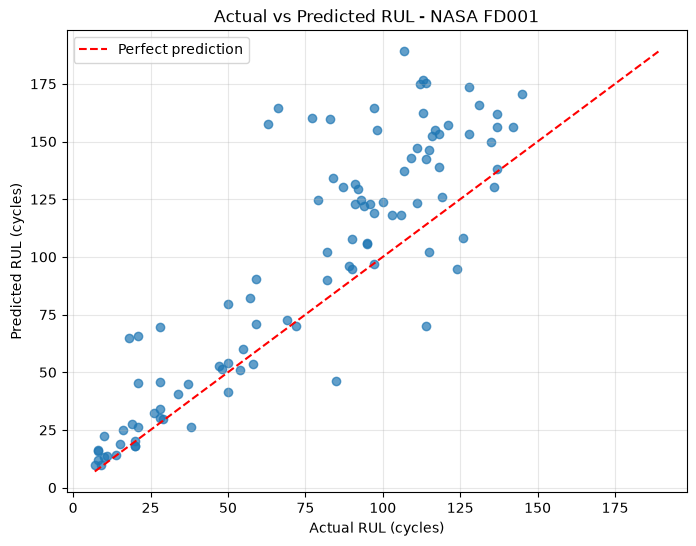

In [55]:
plt.figure(figsize = (8, 6))

plt.scatter(y_test, y_pred, alpha = 0.7)

# Perfect prediction reference line
limits = [
    min(y_test.min(), y_pred.min()),
    max(y_test.max(), y_pred.max())
]

plt.plot(limits, limits, "r--", label = "Perfect prediction")

plt.xlabel("Actual RUL (cycles)")
plt.ylabel("Predicted RUL (cycles)")
plt.title("Actual vs Predicted RUL - NASA FD001")
plt.legend()
plt.grid(alpha = 0.3)

plt.show()

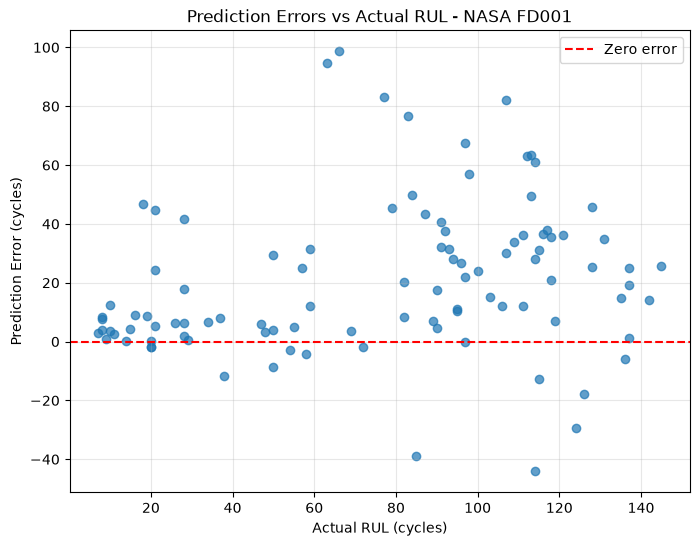

In [56]:
plt.figure(figsize = (8, 6))

plt.scatter(y_test, errors, alpha = 0.7)

# Zero error means a perfect prediction
plt.axhline(y = 0, color = "red", linestyle = "--", label = "Zero error")

plt.xlabel("Actual RUL (cycles)")
plt.ylabel("Prediction Error (cycles)")
plt.title("Prediction Errors vs Actual RUL - NASA FD001")
plt.legend()
plt.grid(alpha = 0.3)

plt.show()

In [58]:
# Create a directory for saved model artifacts
artifacts_dir = Path("../artifacts")
artifacts_dir.mkdir(parents = True, exist_ok = True)

print("Artifacts directory:", artifacts_dir.resolve())

Artifacts directory: C:\Users\xiluv\OneDrive - University of Johannesburg\Documents\predictive-maintenance-rul\artifacts


In [59]:
# Save the trained neural network weights
model_path = artifacts_dir / "rul_model.pth"

torch.save(final_model.state_dict(), model_path)

print("Model saved to:", model_path.resolve())

Model saved to: C:\Users\xiluv\OneDrive - University of Johannesburg\Documents\predictive-maintenance-rul\artifacts\rul_model.pth


In [61]:
# Save the fitted scaler
scaler_path = artifacts_dir / "rul_scaler.pkl"

joblib.dump(final_scaler, scaler_path)

print("Scaler saved to:", scaler_path.resolve())

Scaler saved to: C:\Users\xiluv\OneDrive - University of Johannesburg\Documents\predictive-maintenance-rul\artifacts\rul_scaler.pkl


In [62]:
# Load the saved model into a new instance
loaded_model = ComparisonRULPredictor(input_size = 17)

loaded_model.load_state_dict(
    torch.load(model_path, weights_only = True)
)

loaded_model.eval()

# Load the saved scaler
loaded_scaler = joblib.load(scaler_path)

print("Model and scaler loaded successfully!")

Model and scaler loaded successfully!


In [63]:
# Generate predictions using the loaded model
with torch.no_grad():
    loaded_predictions = loaded_model(X_test_tensor)

# Compare with the original model's predictions
predictions_match = torch.allclose(
    test_predictions,
    loaded_predictions
)

print("Predictions match:", predictions_match)
print("Original prediction:", test_predictions[0].item())
print("Loaded prediction:", loaded_predictions[0].item())

Predictions match: True
Original prediction: 174.98744201660156
Loaded prediction: 174.98744201660156


In [65]:
feature_path = artifacts_dir / "feature_columns.json"

with open(feature_path, "w") as f:
    json.dump(feature_columns, f, indent=4)

print("Feature columns saved:", len(feature_columns))

Feature columns saved: 17
